In [1]:
import numpy as np 
import pandas as pd 
import os
import matplotlib.pyplot as plt
import glob
import nibabel as nib
import cv2
import imageio
from tqdm.notebook import tqdm
from ipywidgets import *
from PIL import Image
from fastai.basics import *
from fastai.vision.all import *
from fastai.data.transforms import *

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.3
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [3]:
# Create a meta file for nii files processing

file_list = []
for dirname, _, filenames in os.walk('/kaggle/input/liver-tumor-segmentation'):
    for filename in filenames:
#         print(os.path.join(dirname, filename))
        file_list.append((dirname,filename)) 

for dirname, _, filenames in os.walk('/kaggle/input/liver-tumor-segmentation-part-2'):
    for filename in filenames:
        file_list.append((dirname,filename)) 

df_files = pd.DataFrame(file_list, columns =['dirname', 'filename']) 
df_files.sort_values(by=['filename'], ascending=True)    

,dirname,filename
89,/kaggle/input/liver-tumor-segmentation/segmentations,segmentation-0.nii
81,/kaggle/input/liver-tumor-segmentation/segmentations,segmentation-1.nii
142,/kaggle/input/liver-tumor-segmentation/segmentations,segmentation-10.nii
31,/kaggle/input/liver-tumor-segmentation/segmentations,segmentation-100.nii
45,/kaggle/input/liver-tumor-segmentation/segmentations,segmentation-101.nii
...,...,...
243,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt6,volume-95.nii
222,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt6,volume-96.nii
217,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt6,volume-97.nii
252,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt6,volume-98.nii


In [4]:
# Map CT scan and label 

df_files["mask_dirname"] = "" ; df_files["mask_filename"] = ""

for i in range(131):
    ct = f"volume-{i}.nii"
    mask = f"segmentation-{i}.nii"
    
    df_files.loc[df_files['filename'] == ct, 'mask_filename'] = mask
    df_files.loc[df_files['filename'] == ct, 'mask_dirname'] = "../input/liver-tumor-segmentation/segmentations"

df_files_test= df_files[df_files.mask_filename=='']
# drop segment rows
df_files = df_files[df_files.mask_filename != ''].sort_values(by=['filename']).reset_index(drop=True) 
print(len(df_files))
df_files
#df_files_test

131


,dirname,filename,mask_dirname,mask_filename
0,/kaggle/input/liver-tumor-segmentation/volume_pt1,volume-0.nii,../input/liver-tumor-segmentation/segmentations,segmentation-0.nii
1,/kaggle/input/liver-tumor-segmentation/volume_pt1,volume-1.nii,../input/liver-tumor-segmentation/segmentations,segmentation-1.nii
2,/kaggle/input/liver-tumor-segmentation/volume_pt1,volume-10.nii,../input/liver-tumor-segmentation/segmentations,segmentation-10.nii
3,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt6,volume-100.nii,../input/liver-tumor-segmentation/segmentations,segmentation-100.nii
4,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt8,volume-101.nii,../input/liver-tumor-segmentation/segmentations,segmentation-101.nii
...,...,...,...,...
126,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt6,volume-95.nii,../input/liver-tumor-segmentation/segmentations,segmentation-95.nii
127,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt6,volume-96.nii,../input/liver-tumor-segmentation/segmentations,segmentation-96.nii
128,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt6,volume-97.nii,../input/liver-tumor-segmentation/segmentations,segmentation-97.nii
129,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt6,volume-98.nii,../input/liver-tumor-segmentation/segmentations,segmentation-98.nii


In [5]:
def read_nii(filepath):
    '''
    Reads .nii file and returns pixel array
    '''
    ct_scan = nib.load(filepath)
    array   = ct_scan.get_fdata()
    array   = np.rot90(np.array(array))
    return(array)

In [6]:
# Read sample
sample = 0
sample_ct   = read_nii(df_files.loc[sample,'dirname']+"/"+df_files.loc[sample,'filename'])
sample_mask  = read_nii(df_files.loc[sample,'mask_dirname']+"/"+df_files.loc[sample,'mask_filename'])
print(sample_ct.shape) 
print(sample_mask.shape)
print(df_files.loc[sample,'dirname']+"/"+df_files.loc[sample,'filename'])

(512, 512, 75)
(512, 512, 75)
/kaggle/input/liver-tumor-segmentation/volume_pt1/volume-0.nii


In [7]:
print(np.amin(sample_ct), np.amax(sample_ct))
print(np.amin(sample_mask), np.amax(sample_mask))

-3024.0 1410.0
0.0 2.0


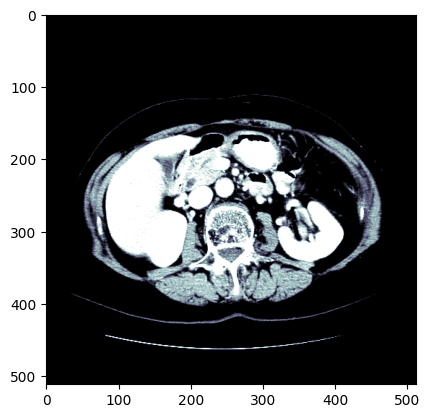

In [8]:
# Preprocess the nii file 
# Source https://docs.fast.ai/medical.imaging

dicom_windows = types.SimpleNamespace(
    brain=(80,40),
    subdural=(254,100),
    stroke=(8,32),
    brain_bone=(2800,600),
    brain_soft=(375,40),
    lungs=(1500,-600),
    mediastinum=(350,50),
    abdomen_soft=(400,50),
    liver=(150,30),
    spine_soft=(250,50),
    spine_bone=(1800,400),
    custom = (200,60)
)

@patch
def windowed(self:Tensor, w, l):
    px = self.clone()
    px_min = l - w//2
    px_max = l + w//2
    px[px<px_min] = px_min
    px[px>px_max] = px_max
    return (px-px_min) / (px_max-px_min)

plt.imshow(tensor(sample_ct[...,50].astype(np.float32)).windowed(*dicom_windows.liver), cmap=plt.cm.bone);

In [9]:
def plot_sample(array_list, color_map = 'nipy_spectral'):
    '''
    Plots and a slice with all available annotations
    '''
    fig = plt.figure(figsize=(18,15))

    plt.subplot(1,4,1)
    plt.imshow(array_list[0], cmap='bone')
    plt.title('Original Image')
    
    plt.subplot(1,4,2)
    plt.imshow(tensor(array_list[0].astype(np.float32)).windowed(*dicom_windows.liver), cmap='bone');
    plt.title('Windowed Image')
    
    plt.subplot(1,4,3)
    plt.imshow(array_list[1], alpha=0.5, cmap=color_map)
    plt.title('Mask')
    
    plt.subplot(1,4,4)
    plt.imshow(array_list[0], cmap='bone')
    plt.imshow(array_list[1], alpha=0.5, cmap=color_map)
    plt.title('Liver & Mask')


    plt.show()

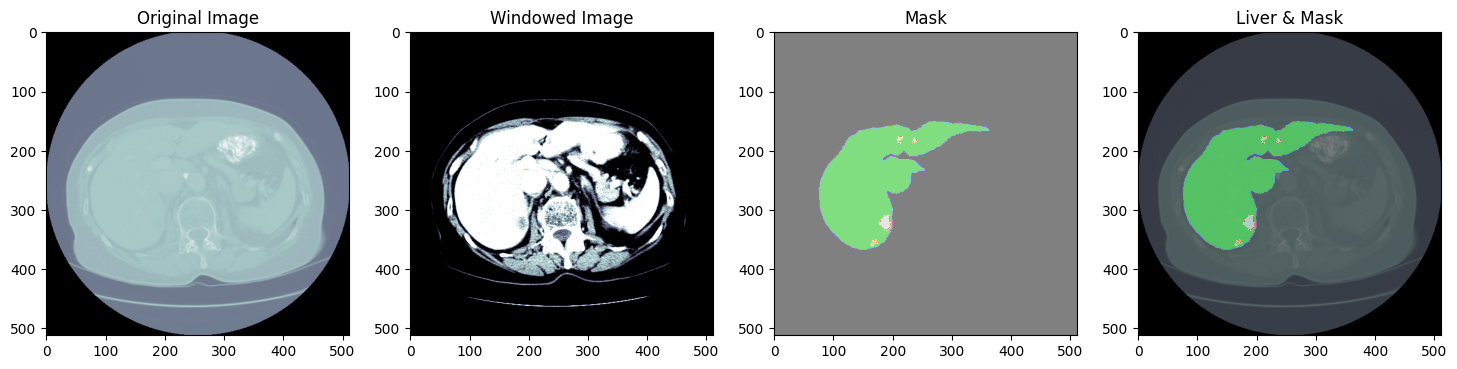

In [10]:
sample=58
sample_slice = tensor(sample_ct[...,sample].astype(np.float32))

plot_sample([sample_ct[...,sample], sample_mask[...,sample]])

In [11]:
# Check the mask values
mask = Image.fromarray(sample_mask[...,sample].astype('uint8'), mode="L")
unique, counts = np.unique(mask, return_counts=True)
print( np.array((unique, counts)).T)

[[     0 234972]
 [     1  26634]
 [     2    538]]


<Axes: >

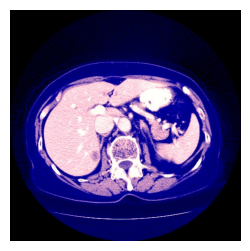

In [12]:
# Preprocessing functions
# Source https://docs.fast.ai/medical.imaging

class TensorCTScan(TensorImageBW): _show_args = {'cmap':'bone'}

@patch
def freqhist_bins(self:Tensor, n_bins=100):
    ''''"A function to split the range of pixel values into groups, 
    such that each group has around the same number of pixels"'''
    imsd = self.view(-1).sort()[0]
    t = torch.cat([tensor([0.001]),
                   torch.arange(n_bins).float()/n_bins+(1/2/n_bins),
                   tensor([0.999])])
    t = (len(imsd)*t).long()
    return imsd[t].unique()
    
@patch
def hist_scaled(self:Tensor, brks=None):
    "Scales a tensor using `freqhist_bins` to values between 0 and 1"
    if self.device.type=='cuda': return self.hist_scaled_pt(brks)
    if brks is None: brks = self.freqhist_bins()
    ys = np.linspace(0., 1., len(brks))
    x = self.numpy().flatten()
    x = np.interp(x, brks.numpy(), ys)
    return tensor(x).reshape(self.shape).clamp(0.,1.)
    
    
@patch
def to_nchan(x:Tensor, wins, bins=None):
    res = [x.windowed(*win) for win in wins]
    if not isinstance(bins,int) or bins!=0: res.append(x.hist_scaled(bins).clamp(0,1))
    dim = [0,1][x.dim()==3]
    return TensorCTScan(torch.stack(res, dim=dim))

@patch
def save_jpg(x:(Tensor), path, wins, bins=None, quality=90):
    fn = Path(path).with_suffix('.jpg')
    x = (x.to_nchan(wins, bins)*255).byte()
    im = Image.fromarray(x.permute(1,2,0).numpy(), mode=['RGB','CMYK'][x.shape[0]==4])
    im.save(fn, quality=quality)

_,axs=subplots(1,1)

sample_slice.save_jpg('test.jpg', [dicom_windows.liver,dicom_windows.custom])
show_image(Image.open('test.jpg'), ax=axs[0])

In [13]:
df_files_1=df_files[0:30]
df_files_1

,dirname,filename,mask_dirname,mask_filename
0,/kaggle/input/liver-tumor-segmentation/volume_pt1,volume-0.nii,../input/liver-tumor-segmentation/segmentations,segmentation-0.nii
1,/kaggle/input/liver-tumor-segmentation/volume_pt1,volume-1.nii,../input/liver-tumor-segmentation/segmentations,segmentation-1.nii
2,/kaggle/input/liver-tumor-segmentation/volume_pt1,volume-10.nii,../input/liver-tumor-segmentation/segmentations,segmentation-10.nii
3,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt6,volume-100.nii,../input/liver-tumor-segmentation/segmentations,segmentation-100.nii
4,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt8,volume-101.nii,../input/liver-tumor-segmentation/segmentations,segmentation-101.nii
5,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt8,volume-102.nii,../input/liver-tumor-segmentation/segmentations,segmentation-102.nii
6,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt8,volume-103.nii,../input/liver-tumor-segmentation/segmentations,segmentation-103.nii
7,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt8,volume-104.nii,../input/liver-tumor-segmentation/segmentations,segmentation-104.nii
8,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt8,volume-105.nii,../input/liver-tumor-segmentation/segmentations,segmentation-105.nii
9,/kaggle/input/liver-tumor-segmentation-part-2/volume_pt8,volume-106.nii,../input/liver-tumor-segmentation/segmentations,segmentation-106.nii


In [14]:
import random
!pip install ipywidgets==7.6.5

GENERATE_JPG_FILES = True   # warning: generation takes ~ 1h

if GENERATE_JPG_FILES:
    path = Path(".")

    os.makedirs('train_images', exist_ok=True)
    os.makedirs('train_masks', exist_ok=True)

    # Randomly select 1/3 of the indices
    random_indices = random.sample(range(len(df_files)), len(df_files) // 2)

    for ii in tqdm(random_indices):  # take 1/3 nii files for training
        curr_ct = read_nii(df_files.loc[ii, 'dirname'] + "/" + df_files.loc[ii, 'filename'])
        curr_mask = read_nii(df_files.loc[ii, 'mask_dirname'] + "/" + df_files.loc[ii, 'mask_filename'])
        curr_file_name = str(df_files.loc[ii, 'filename']).split('.')[0]
        curr_dim = curr_ct.shape[2]  # 512, 512, curr_dim

        for curr_slice in range(0, curr_dim, 2):  # export every 2nd slice for training
            data = tensor(curr_ct[..., curr_slice].astype(np.float32))
            mask = Image.fromarray(curr_mask[..., curr_slice].astype('uint8'), mode="L")
            data.save_jpg(f"train_images/{curr_file_name}_slice_{curr_slice}.jpg", [dicom_windows.liver, dicom_windows.custom])
            mask.save(f"train_masks/{curr_file_name}_slice_{curr_slice}_mask.png")
else:
    path = Path("../input/liver-segmentation-with-fastai-v2")  # read jpg from saved kernel output


  Obtaining dependency information for ipywidgets==7.6.5 from https://files.pythonhosted.org/packages/6b/bb/285066ddd710779cb69f03d42fa72fbfe4352b4895eb6abab551eae1535a/ipywidgets-7.6.5-py2.py3-none-any.whl.metadata
  Obtaining dependency information for widgetsnbextension~=3.5.0 from https://files.pythonhosted.org/packages/d7/31/7c1107fa30c621cd1d36410e9bbab86f6a518dc208aaec01f02ac6d5c2d2/widgetsnbextension-3.5.2-py2.py3-none-any.whl.metadata
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.8/121.8 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 31.0 MB/s eta 0:00:0000:01
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.6
    Uninstalling widgetsnbextension-3.6.6:
      Successfully uninstalled widgetsnbextension-3.6.6
  Attempting uninstall: ipywidgets
    Found existing installation: ipywidgets 7.7.1
    Uninstalling ipywidgets-7.7.1:
      Successfully uninstalled ipywidgets-7.7.1


  0%|          | 0/65 [00:00<?, ?it/s]

pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1
pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1
pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1
pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1


In [15]:
import os
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
from sklearn.model_selection import train_test_split

# Set the directories
images_dir = 'train_images'
masks_dir = 'train_masks'

# Get the list of image file names
all_image_file_names = sorted(os.listdir(images_dir))

# Randomly select 9000 images
selected_image_file_names = random.sample(all_image_file_names, 9000)

# Load selected images and masks with resizing
target_size = (128, 128)
images = [np.array(Image.open(os.path.join(images_dir, fname)).resize(target_size)) for fname in selected_image_file_names]

# Adjust file extension for masks
mask_file_names = [fname.replace('.jpg', '_mask.png') for fname in selected_image_file_names]
masks = [np.array(Image.open(os.path.join(masks_dir, fname)).resize(target_size)) for fname in mask_file_names]

# Convert the lists to numpy arrays
images = np.array(images)
masks = np.array(masks)

# Normalize images to [0, 1]
images = images / 255.0

# Reshape masks to include a channel dimension
masks = masks.reshape((masks.shape[0], masks.shape[1], masks.shape[2], 1))


In [16]:
# Split the data into training, validation, and test sets
# 70% training, 20% validation, 10% test
x_train, x_temp, y_train, y_temp = train_test_split(images, masks, test_size=0.3, random_state=42)
x_valid, x_test, y_valid, y_test = train_test_split(x_temp, y_temp, test_size=1/3, random_state=42)

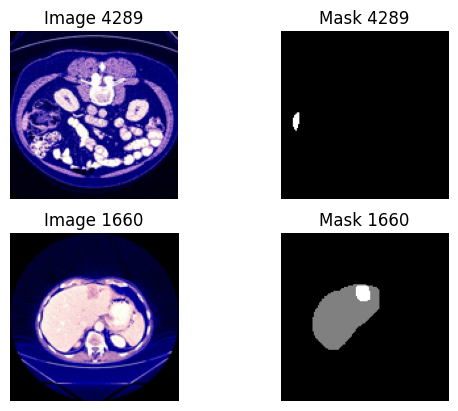

In [17]:
import matplotlib.pyplot as plt

# Function to display images and masks
def display_images_and_masks(images, masks, num_samples=2):
    # Randomly select samples
    sample_indices = random.sample(range(images.shape[0]), num_samples)

    for i in range(num_samples):
        index = sample_indices[i]

        # Display the image
        plt.subplot(num_samples, 2, 2 * i + 1)
        plt.imshow(images[index])
        plt.title("Image {}".format(index))
        plt.axis("off")

        # Display the mask
        plt.subplot(num_samples, 2, 2 * i + 2)
        plt.imshow(masks[index].squeeze(), cmap='gray')
        plt.title("Mask {}".format(index))
        plt.axis("off")
    plt.show()

    
# Display two random images and masks
display_images_and_masks(x_train, y_train)


In [18]:
y_train.shape, x_train.shape

((6300, 128, 128, 1), (6300, 128, 128, 3))

In [19]:
from tensorflow import keras
from tensorflow.keras import layers

def create_fcn_model(input_shape=(128, 128, 3), target_shape=(128, 128, 1)):
    model = keras.Sequential()

    # Encoder
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=input_shape))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(256, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(256, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    # Decoder with Skip Connections
    model.add(layers.UpSampling2D((2, 2)))
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())

    model.add(layers.UpSampling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())

    model.add(layers.UpSampling2D((2, 2)))
    model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())

    # Output layer
    model.add(layers.Conv2D(1, (1, 1), activation='sigmoid'))  # Assuming binary classification

    # Crop to match the target shape
    crop_height = (model.output_shape[1] - target_shape[0]) // 2
    crop_width = (model.output_shape[2] - target_shape[1]) // 2
    model.add(layers.Cropping2D(cropping=((crop_height, crop_height), (crop_width, crop_width))))

    return model
# Create the FCN model
model = create_fcn_model()

# Display the model summary
model.summary()
model.save('fcn_model.h5')

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 64)      1792      
                                                                 
 batch_normalization (Batch  (None, 128, 128, 64)      256       
 Normalization)                                                  
                                                                 
 conv2d_1 (Conv2D)           (None, 128, 128, 64)      36928     
                                                                 
 batch_normalization_1 (Bat  (None, 128, 128, 64)      256       
 chNormalization)                                                
                                                                 
 max_pooling2d (MaxPooling2  (None, 64, 64, 64)        0         
 D)                                                              
                                                        

/opt/conda/lib/python3.10/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


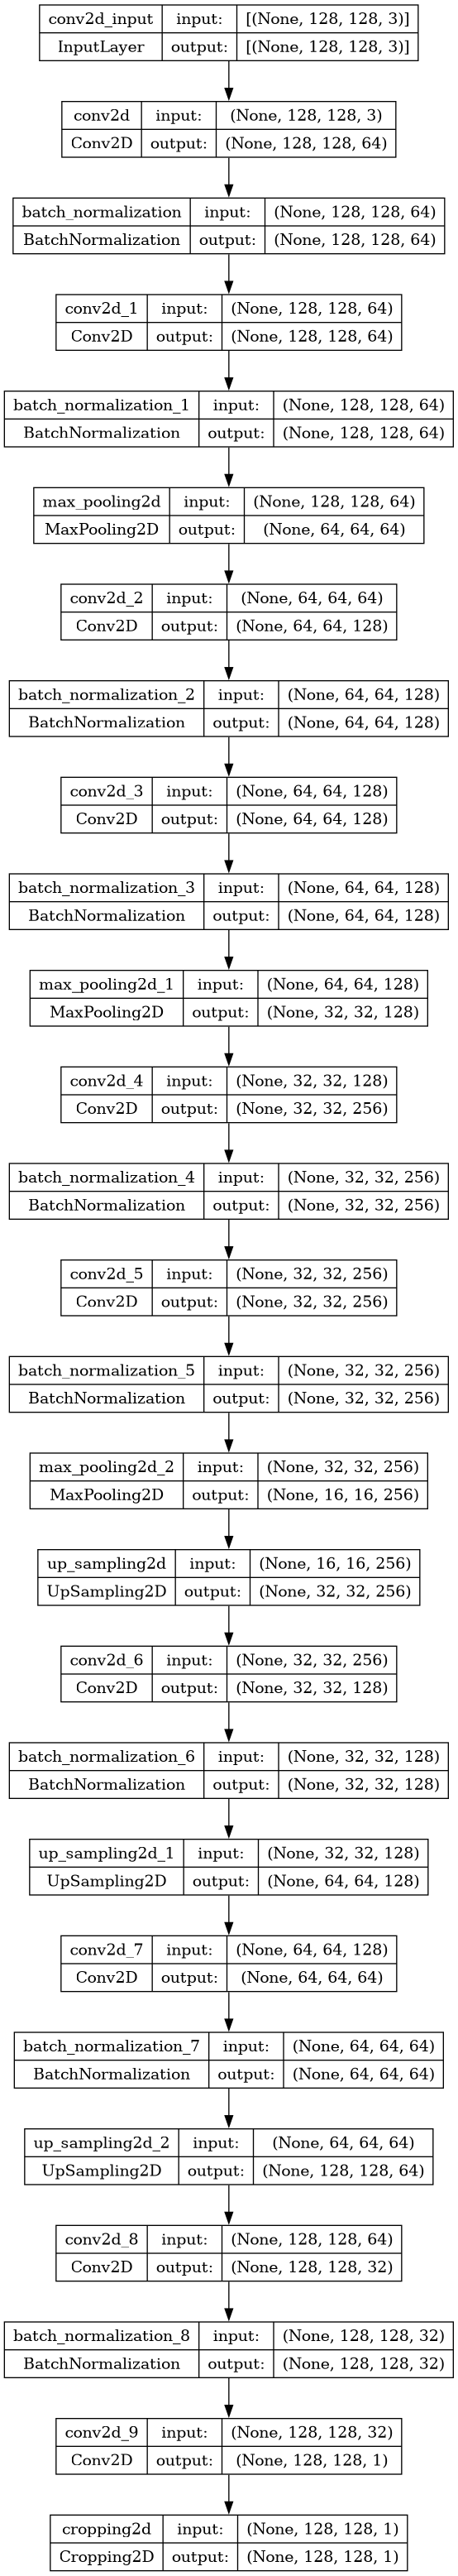

In [20]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [21]:
import tensorflow as tf

def dice_coefficient(y_true, y_pred):
    smooth = 1.0  # Smoothing factor to avoid division by zero
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)
    dice = (2.0 * intersection + smooth) / (union + smooth)
    return dice


In [22]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

checkpoint = tf.keras.callbacks.ModelCheckpoint("fcn_model.h5", monitor='val_loss', verbose=1, patience = 3,save_best_only=True,
                                                save_weights_only=True, mode='auto')
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6)
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir='./logs', histogram_freq=1)

In [23]:
from tensorflow.keras.optimizers import Adam
# Compile the model [0.001,0001, 6e-e]
model.compile(optimizer=Adam(lr = 0.01),loss='binary_crossentropy',
              metrics=[dice_coefficient])

In [24]:
# Train the model
history = model.fit(x_train, y_train, epochs=5, batch_size=16,
          validation_data=(x_valid, y_valid), callbacks=[reduce_lr,checkpoint])
model.save('fcn_model.h5')

Epoch 1/5
394/394 [==============================] - ETA: 0s - loss: 0.2109 - dice_coefficient: 0.2484
Epoch 1: val_loss improved from inf to 0.11205, saving model to fcn_model.h5
394/394 [==============================] - 52s 98ms/step - loss: 0.2109 - dice_coefficient: 0.2484 - val_loss: 0.1121 - val_dice_coefficient: 0.1956 - lr: 0.0010
Epoch 2/5
394/394 [==============================] - ETA: 0s - loss: 0.0310 - dice_coefficient: 0.5660
Epoch 2: val_loss improved from 0.11205 to 0.02793, saving model to fcn_model.h5
394/394 [==============================] - 35s 88ms/step - loss: 0.0310 - dice_coefficient: 0.5660 - val_loss: 0.0279 - val_dice_coefficient: 0.5175 - lr: 0.0010
Epoch 3/5
394/394 [==============================] - ETA: 0s - loss: 0.0145 - dice_coefficient: 0.7077
Epoch 3: val_loss improved from 0.02793 to 0.01991, saving model to fcn_model.h5
394/394 [==============================] - 38s 97ms/step - loss: 0.0145 - dice_coefficient: 0.7077 - val_loss: 0.0199 - val_dice

/opt/conda/lib/python3.10/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


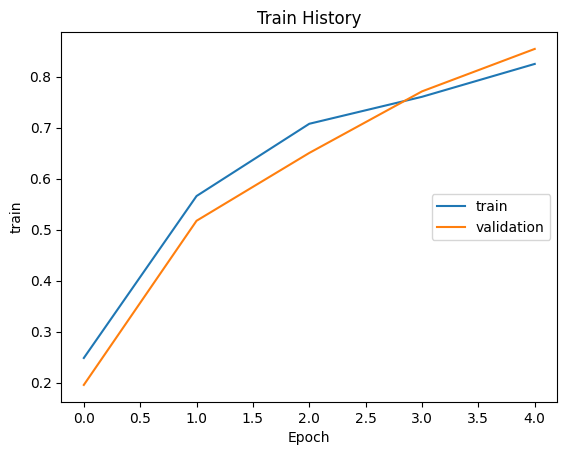

In [25]:
import matplotlib.pyplot as plt
def show_history(history, train, validation):
    plt.plot(history.history[train])
    plt.plot(history.history[validation])
    plt.title('Train History')
    plt.ylabel('train')
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='center right')
    plt.show()
show_history(history, 'dice_coefficient', 'val_dice_coefficient')

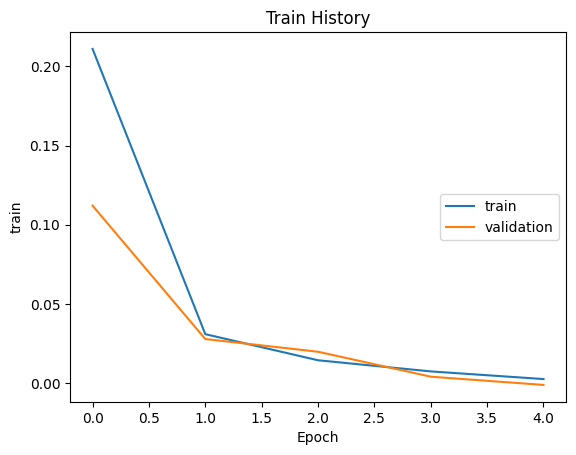

In [26]:
show_history(history, 'loss', 'val_loss')

In [27]:
scores = model.evaluate(x_valid, y_valid)
scores[1]

57/57 [==============================] - 5s 51ms/step - loss: -0.0010 - dice_coefficient: 0.8609


0.8608976602554321

In [28]:
prediction = model.predict(x_test)
# print(prediction)
# print(y_test)

29/29 [==============================] - 2s 75ms/step


In [29]:
test_scores = model.evaluate(x_test, y_test)
test_scores[1]

29/29 [==============================] - 1s 51ms/step - loss: -6.0249e-06 - dice_coefficient: 0.8498


0.8498438000679016

1/1 [==============================] - 1s 573ms/step


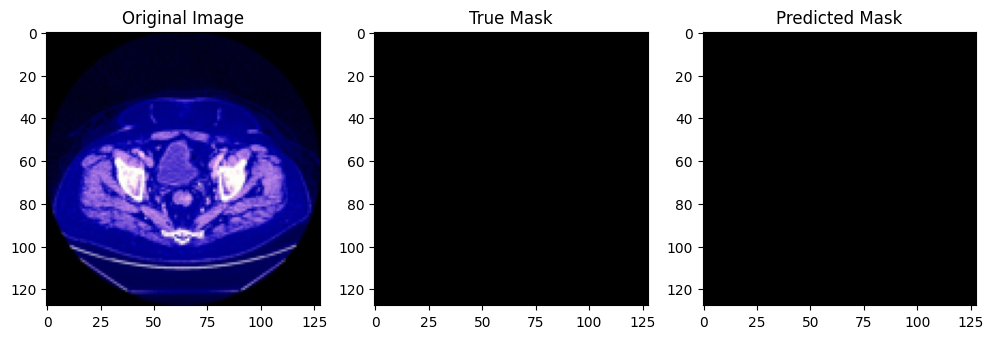

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming you have x_test and y_test
# Replace this with the actual index of the image you want to visualize
image_index = 431

# Load the image and true mask
input_image = x_test[image_index]
true_mask = y_test[image_index]

# Obtain the predicted mask from model2
predicted_mask = model.predict(np.expand_dims(input_image, axis=0))[0]

# Threshold the predicted mask (assuming it's a binary mask)
threshold = 0.5  # Adjust this threshold based on your model's output
predicted_mask_binary = (predicted_mask > threshold).astype(np.uint8)

# Plotting
plt.figure(figsize=(12, 4))

# Plot original image
plt.subplot(1, 3, 1)
plt.imshow(input_image)
plt.title('Original Image')

# Plot true mask
plt.subplot(1, 3, 2)
plt.imshow(true_mask[:, :, 0], cmap='gray')
plt.title('True Mask')

# Plot predicted mask
plt.subplot(1, 3, 3)
plt.imshow(predicted_mask_binary[:, :, 0], cmap='gray')
plt.title('Predicted Mask')

plt.show()


In [31]:
import tensorflow.keras.backend as K
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import MeanIoU
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate

# Define Dice coefficient as a metric
def dice_coefficient(y_true, y_pred, smooth=1):
    intersection = K.sum(K.abs(y_true * y_pred), axis=-1)
    union = K.sum(y_true, axis=-1) + K.sum(y_pred, axis=-1)
    return (2. * intersection + smooth) / (union + smooth)

# U-Net model architecture for liver segmentation
def unet_model(input_shape=(128, 128, 3)):
    inputs = Input(input_shape)

    # Encoder
    conv1 = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    conv1 = Conv2D(32, (3, 3), activation='relu', padding='same')(conv1)
    pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)

    conv2 = Conv2D(64, (3, 3), activation='relu', padding='same')(pool1)
    conv2 = Conv2D(64, (3, 3), activation='relu', padding='same')(conv2)
    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)

    # Middle
    conv3 = Conv2D(128, (3, 3), activation='relu', padding='same')(pool2)
    conv3 = Conv2D(128, (3, 3), activation='relu', padding='same')(conv3)

    # Decoder
    up4 = UpSampling2D(size=(2, 2))(conv3)
    up4 = Conv2D(64, (3, 3), activation='relu', padding='same')(up4)
    up4 = Conv2D(64, (3, 3), activation='relu', padding='same')(up4)
    merge4 = concatenate([conv2, up4], axis=3)

    up5 = UpSampling2D(size=(2, 2))(merge4)
    up5 = Conv2D(32, (3, 3), activation='relu', padding='same')(up5)
    up5 = Conv2D(32, (3, 3), activation='relu', padding='same')(up5)
    merge5 = concatenate([conv1, up5], axis=3)

    # Output layer
    outputs = Conv2D(1, (1, 1), activation='sigmoid')(merge5)

    model1 = Model(inputs=inputs, outputs=outputs)

    return model1

# Build the U-Net model
model1 = unet_model()

# Display the model summary
model1.summary()
model1.save('unet_model.h5')

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 128, 128, 3)]        0         []                            
                                                                                                  
 conv2d_10 (Conv2D)          (None, 128, 128, 32)         896       ['input_1[0][0]']             
                                                                                                  
 conv2d_11 (Conv2D)          (None, 128, 128, 32)         9248      ['conv2d_10[0][0]']           
                                                                                                  
 max_pooling2d_3 (MaxPoolin  (None, 64, 64, 32)           0         ['conv2d_11[0][0]']           
 g2D)                                                                                         

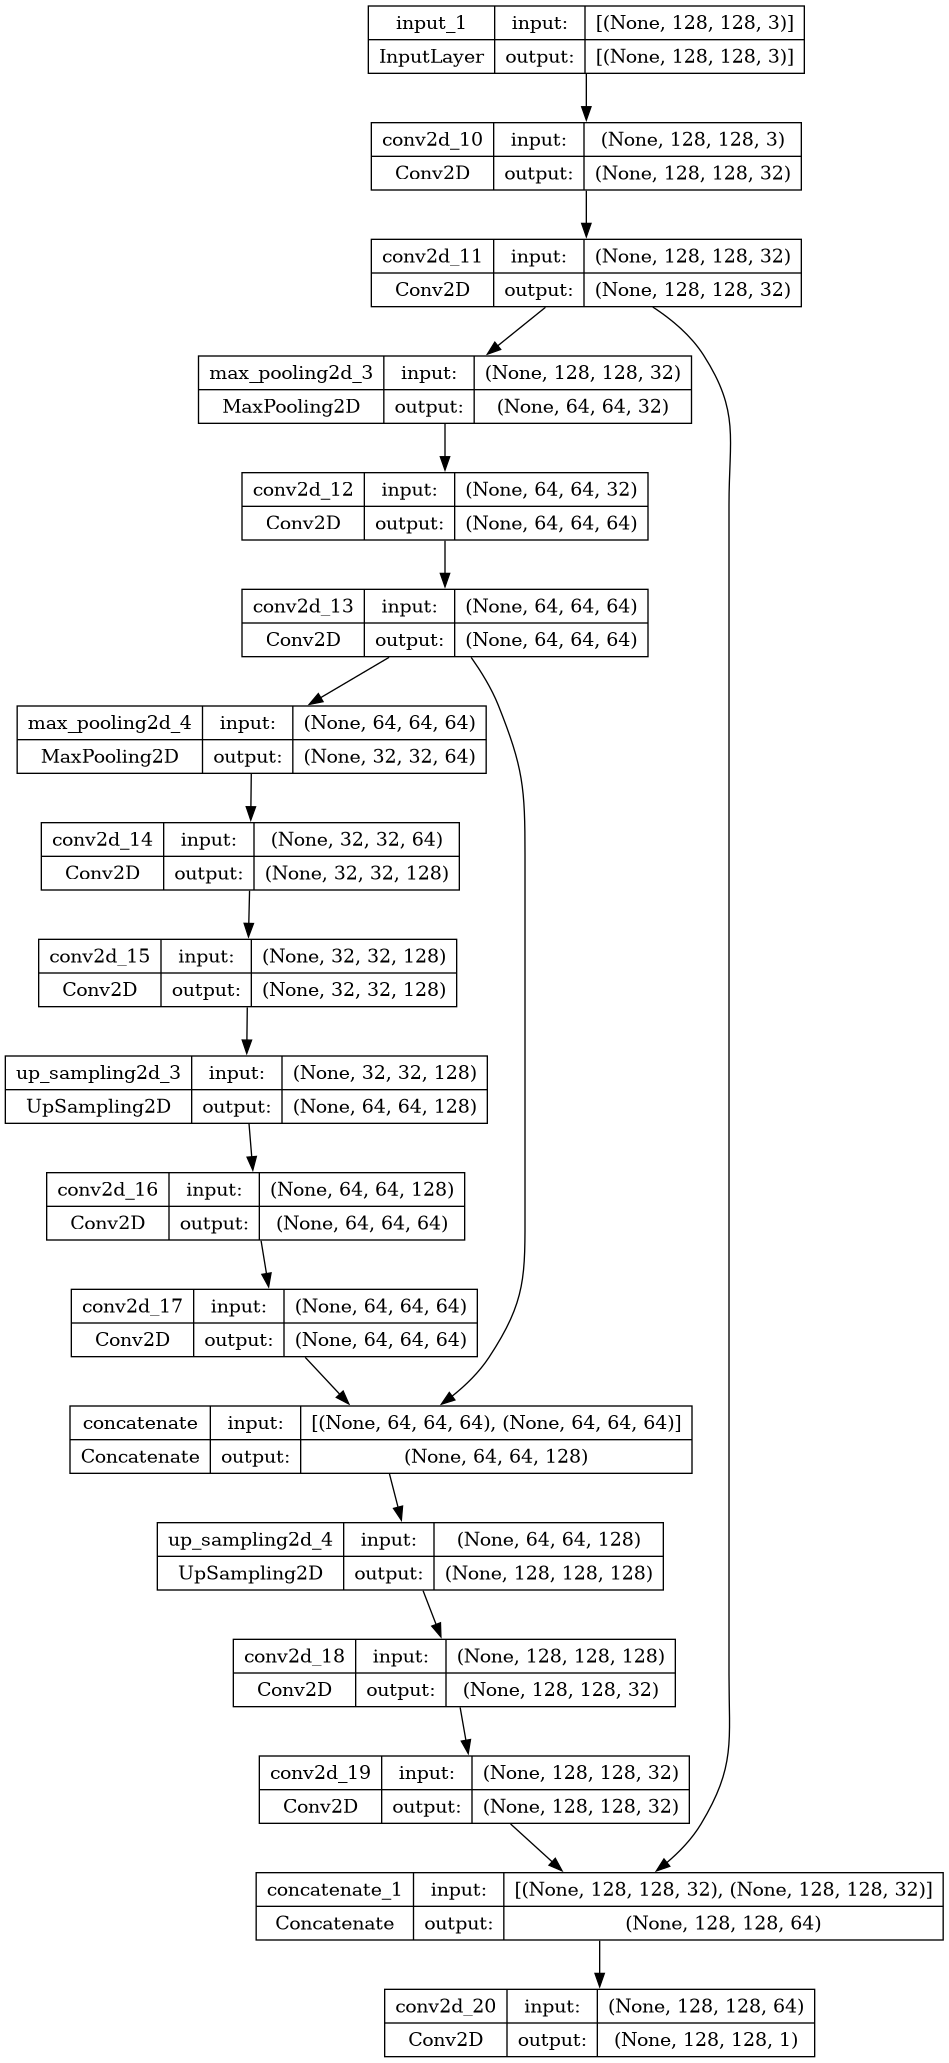

In [34]:
from tensorflow.keras.utils import plot_model
tf.keras.utils.plot_model(model1, show_shapes=True)
# Assuming you have created the model using the create_fcn_model function
# model1 = create_unet_model()

# Save the model architecture plot to a file
# plot_model(model1, to_file='unet_model.png', show_shapes=False)

In [32]:
checkpoint = tf.keras.callbacks.ModelCheckpoint("unet_model.h5", monitor='val_loss', verbose=1, patience = 3,save_best_only=True,
                                                mode='auto')

In [33]:
from tensorflow.keras.optimizers import Adam
# Compile the model [0.001,0001, 6e-e]
model1.compile(optimizer=Adam(lr=0.001, beta_1=0.9, beta_2=0.999),
              loss= 'mean_absolute_error', metrics=[dice_coefficient])

In [34]:
# Train the model
history1 = model1.fit(x_train, y_train, epochs=5, batch_size=16,
          validation_data=(x_valid, y_valid), callbacks=[checkpoint])
model1.save('unet_model.h5')

Epoch 1/5
394/394 [==============================] - ETA: 0s - loss: 0.0290 - dice_coefficient: 0.9849
Epoch 1: val_loss improved from inf to 0.02411, saving model to unet_model.h5
394/394 [==============================] - 36s 77ms/step - loss: 0.0290 - dice_coefficient: 0.9849 - val_loss: 0.0241 - val_dice_coefficient: 0.9884
Epoch 2/5
393/394 [============================>.] - ETA: 0s - loss: 0.0241 - dice_coefficient: 0.9884
Epoch 2: val_loss did not improve from 0.02411
394/394 [==============================] - 26s 66ms/step - loss: 0.0241 - dice_coefficient: 0.9884 - val_loss: 0.0241 - val_dice_coefficient: 0.9884
Epoch 3/5
393/394 [============================>.] - ETA: 0s - loss: 0.0241 - dice_coefficient: 0.9884
Epoch 3: val_loss did not improve from 0.02411
394/394 [==============================] - 26s 66ms/step - loss: 0.0241 - dice_coefficient: 0.9884 - val_loss: 0.0241 - val_dice_coefficient: 0.9884
Epoch 4/5
393/394 [============================>.] - ETA: 0s - loss: 0.0

In [35]:
scores1 = model1.evaluate(x_valid, y_valid)
scores1[1]

57/57 [==============================] - 4s 40ms/step - loss: 0.0241 - dice_coefficient: 0.9884


0.988385796546936

In [36]:
prediction1 = model1.predict(x_test)
#print(prediction)
#print(y_test)

29/29 [==============================] - 2s 52ms/step


In [37]:
test_scores1 = model1.evaluate(x_test, y_test)
test_scores1[1]

29/29 [==============================] - 1s 39ms/step - loss: 0.0253 - dice_coefficient: 0.9878


0.9877890348434448

1/1 [==============================] - 0s 282ms/step


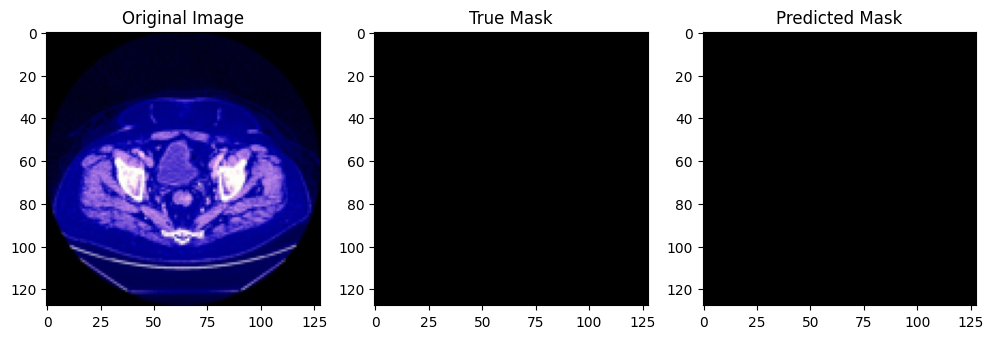

In [38]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming you have x_test and y_test
# Replace this with the actual index of the image you want to visualize
image_index = 431

# Load the image and true mask
input_image = x_test[image_index]
true_mask = y_test[image_index]

# Obtain the predicted mask from model2
predicted_mask = model1.predict(np.expand_dims(input_image, axis=0))[0]

# Threshold the predicted mask (assuming it's a binary mask)
threshold = 0.5  # Adjust this threshold based on your model's output
predicted_mask_binary = (predicted_mask > threshold).astype(np.uint8)

# Plotting
plt.figure(figsize=(12, 4))

# Plot original image
plt.subplot(1, 3, 1)
plt.imshow(input_image)
plt.title('Original Image')

# Plot true mask
plt.subplot(1, 3, 2)
plt.imshow(true_mask[:, :, 0], cmap='gray')
plt.title('True Mask')

# Plot predicted mask
plt.subplot(1, 3, 3)
plt.imshow(predicted_mask[:, :, 0], cmap='gray')
plt.title('Predicted Mask')

plt.show()


In [39]:
def segnet_model(input_shape=(128, 128, 3)):
    model2 = tf.keras.Sequential()

    # Encoder
    model2.add(layers.Conv2D(64, (3, 3), padding='same', input_shape=input_shape))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.Conv2D(64, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))

    model2.add(layers.Conv2D(128, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.Conv2D(128, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))

    model2.add(layers.Conv2D(256, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.Conv2D(256, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.Conv2D(256, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))

    # Decoder
    model2.add(layers.UpSampling2D(size=(2, 2)))
    model2.add(layers.Conv2D(256, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.Conv2D(256, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.Conv2D(256, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))

    model2.add(layers.UpSampling2D(size=(2, 2)))
    model2.add(layers.Conv2D(128, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.Conv2D(128, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))

    model2.add(layers.UpSampling2D(size=(2, 2)))
    model2.add(layers.Conv2D(64, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))
    model2.add(layers.Conv2D(64, (3, 3), padding='same'))
    model2.add(layers.BatchNormalization())
    model2.add(layers.Activation('relu'))

    # Output layer
    model2.add(layers.Conv2D(1, (1, 1), activation='sigmoid', padding='same'))

    return model2

# Create SegNet model
model2 = segnet_model(input_shape=(128, 128, 3))


# Display the model summary
model2.summary()
model2.save('segnet_model2.h5')

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_21 (Conv2D)          (None, 128, 128, 64)      1792      
                                                                 
 batch_normalization_9 (Bat  (None, 128, 128, 64)      256       
 chNormalization)                                                
                                                                 
 activation (Activation)     (None, 128, 128, 64)      0         
                                                                 
 conv2d_22 (Conv2D)          (None, 128, 128, 64)      36928     
                                                                 
 batch_normalization_10 (Ba  (None, 128, 128, 64)      256       
 tchNormalization)                                               
                                                                 
 activation_1 (Activation)   (None, 128, 128, 64)     

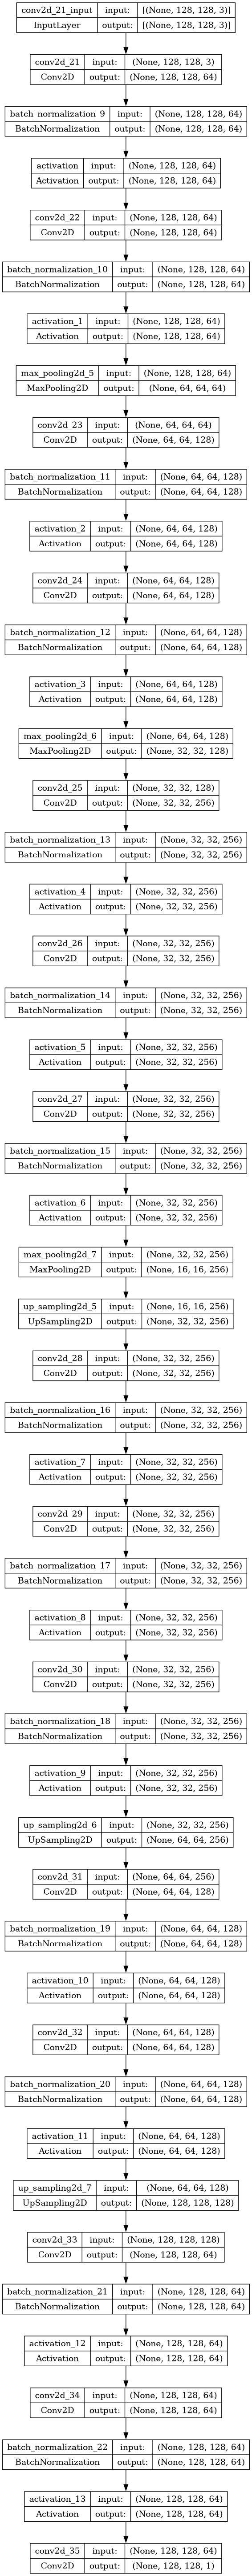

In [40]:
from tensorflow.keras.utils import plot_model
tf.keras.utils.plot_model(model2, show_shapes=True)
# Assuming you have created the model using the create_fcn_model function
#model1 = create_unet_model()

# Save the model architecture plot to a file
#plot_model(model2, to_file='segnet_model.png', show_shapes=False)

In [41]:
checkpoint = tf.keras.callbacks.ModelCheckpoint("segnet_model2.h5", monitor='val_loss', verbose=1, patience = 3,save_best_only=True,
                                                mode='auto')

In [42]:
from tensorflow.keras.optimizers import Adam
# Compile the model [0.001,0001, 6e-e]
model2.compile(optimizer=Adam(lr=0.001, beta_1=0.9, beta_2=0.999),
              loss= 'binary_crossentropy', metrics=[dice_coefficient])

In [43]:
# Train the model
history2 = model2.fit(x_train, y_train, epochs=5, batch_size=16,
          validation_data=(x_valid, y_valid), callbacks=[checkpoint])
model2.save('segnet_model2.h5')

Epoch 1/5
394/394 [==============================] - ETA: 0s - loss: 0.0643 - dice_coefficient: 0.9651
Epoch 1: val_loss improved from inf to 0.09853, saving model to segnet_model2.h5


/opt/conda/lib/python3.10/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


394/394 [==============================] - 101s 226ms/step - loss: 0.0643 - dice_coefficient: 0.9651 - val_loss: 0.0985 - val_dice_coefficient: 0.9864
Epoch 2/5
394/394 [==============================] - ETA: 0s - loss: 0.0289 - dice_coefficient: 0.9886
Epoch 2: val_loss improved from 0.09853 to 0.02921, saving model to segnet_model2.h5
394/394 [==============================] - 83s 211ms/step - loss: 0.0289 - dice_coefficient: 0.9886 - val_loss: 0.0292 - val_dice_coefficient: 0.9915
Epoch 3/5
394/394 [==============================] - ETA: 0s - loss: 0.0214 - dice_coefficient: 0.9918
Epoch 3: val_loss improved from 0.02921 to 0.02377, saving model to segnet_model2.h5
394/394 [==============================] - 83s 211ms/step - loss: 0.0214 - dice_coefficient: 0.9918 - val_loss: 0.0238 - val_dice_coefficient: 0.9911
Epoch 4/5
394/394 [==============================] - ETA: 0s - loss: 0.0130 - dice_coefficient: 0.9935
Epoch 4: val_loss improved from 0.02377 to 0.01070, saving model to se

In [44]:
scores2 = model2.evaluate(x_valid, y_valid)
scores2[1]

57/57 [==============================] - 10s 120ms/step - loss: 0.1716 - dice_coefficient: 0.9881


0.9880971312522888

In [45]:
prediction2 = model2.predict(x_test)
#print(prediction)
#print(y_test)


29/29 [==============================] - 5s 159ms/step


In [46]:
test_scores2 = model2.evaluate(x_test, y_test)
test_scores2[1]

29/29 [==============================] - 4s 127ms/step - loss: 0.1781 - dice_coefficient: 0.9875


0.9875257015228271

1/1 [==============================] - 1s 637ms/step


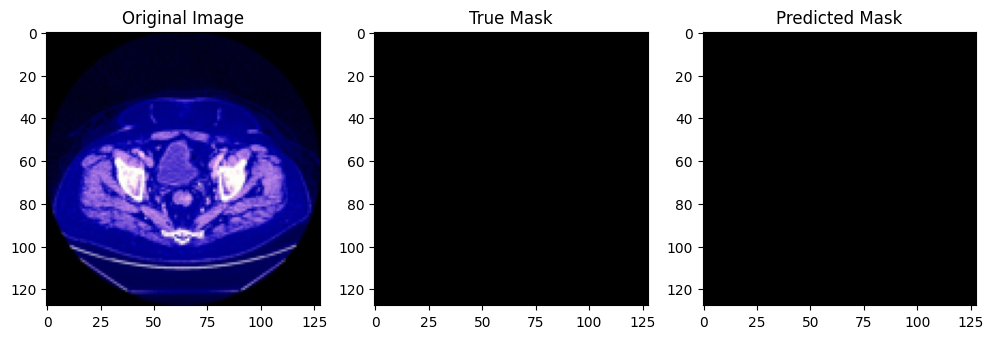

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming you have x_test and y_test
# Replace this with the actual index of the image you want to visualize
image_index = 431

# Load the image and true mask
input_image = x_test[image_index]
true_mask = y_test[image_index]

# Obtain the predicted mask from model2
predicted_mask = model2.predict(np.expand_dims(input_image, axis=0))[0]

# Threshold the predicted mask (assuming it's a binary mask)
threshold = 0.5  # Adjust this threshold based on your model's output
predicted_mask_binary = (predicted_mask > threshold).astype(np.uint8)

# Plotting
plt.figure(figsize=(12, 4))

# Plot original image
plt.subplot(1, 3, 1)
plt.imshow(input_image)
plt.title('Original Image')

# Plot true mask
plt.subplot(1, 3, 2)
plt.imshow(true_mask[:, :, 0], cmap='gray')
plt.title('True Mask')

# Plot predicted mask
plt.subplot(1, 3, 3)
plt.imshow(predicted_mask_binary[:, :, 0], cmap='gray')
plt.title('Predicted Mask')

plt.show()

In [48]:
# Save the trained Keras model to an HDF5 file
model2.save("liver_segmentation_model.h5")

# Create a download link for the saved model file
from IPython.display import FileLink
display(FileLink("liver_segmentation_model.h5"))


/kaggle/working/liver_segmentation_model.h5